In [1]:
import pandas as pd
from pandas.api.types import CategoricalDtype
import numpy as np
import json
import time
import xarray as xr
import scipy.signal as signal
import glob
import os
import xgboost as xgb
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score, StratifiedKFold, permutation_test_score, GridSearchCV
from sklearn.metrics import classification_report, recall_score, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,make_scorer,balanced_accuracy_score, f1_score

import matplotlib.gridspec as gridspec
from matplotlib.ticker import FormatStrFormatter
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import seaborn as sns

from matplotlib.ticker import MultipleLocator


data_dir = '/home/lukeew/Local_work/data/01_SLW_xgb'
reference_dir = data_dir + '/CHCH_v6_reference/'
reference_mask_dir = reference_dir + 'processed{}/'
model_save_dir = reference_dir + 'models/'

model_mask_dir = data_dir + '/CHCH_v6_model/{}/model_processed_{}/'


In [2]:

c1 = (0.03137254901960784,0.18823529411764706,0.4196078431372549,1) #MPC
c2 = (0.8,0,0,1)     #SLWC
c3 = (0,0,1)    #WLWC
c4 = (0.8,0.8,0)    #IC
c5 = (0.7,0.7,0.7) # Unknown

### Single day

In [9]:
date = '20210521'
model_name = 'AG_XGBoost'

infile_ref = reference_mask_dir.format(date[:-2])+str(date)+'.nc'
print('  <--- ' + infile_ref)
ds_ref = xr.open_dataset(infile_ref)

infile_mod = model_mask_dir.format(model_name,date[:-2])+str(date)+'.nc'
print('  <--- ' + infile_mod)
ds_mod = xr.open_dataset(infile_mod)

  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/processed202105/20210521.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_model_processed/AG_XGBoost/model_processed_202105/20210521.nc


In [10]:
ds_mod

<xarray.Dataset>
Dimensions:           (time: 288, level: 300)
Coordinates:
  * time              (time) datetime64[ns] 2021-05-21T00:02:29.999991 ... 20...
    zfull             (level) float64 ...
Dimensions without coordinates: level
Data variables:
    backscatter       (time, level) float64 ...
    cloud_mask        (time, level) int8 ...
    temp              (time, level) float64 ...
    classified_peaks  (time, level) float64 ...
    slwc              (time, level) int8 ...
    slwc_t            (time) int8 ...

In [3]:
slwc_ref = ds_ref.slwc
slwc_t_ref = slwc_ref.max(dim='level')

slwc_t_mod = ds_mod.slwc_t
class_pks = ds_mod.classified_peaks
pks_t = ~class_pks.max(dim='level').isnull()  # True if peaks are present, false if no peaks present

In [32]:
print('{:.0f} cloudy time steps (with peaks detected), out of {} time steps ({:.1f}%)'.format(pks_t.sum(),len(pks_t),100*pks_t.mean()))
print('Ref: {:.0f} time steps have SLWC, out of {} total time steps ({:.1f}%)'.format(slwc_t_ref.sum(),len(slwc_t_ref),100*slwc_t_ref.mean()))
print('Ref: {:.0f} time steps have SLCC, out of {} cloudy time steps ({:.1f}%)'.format(slwc_t_ref[pks_t].sum(),len(slwc_t_ref[pks_t]),100*slwc_t_ref[pks_t].mean()))
print('Model: {:.0f} time steps have SLCC, out of {} total time steps ({:.1f}%)'.format(slwc_t_mod.sum(),len(slwc_t_mod),100*slwc_t_mod.mean()))
print('Model: {:.0f} time steps have SLCC, out of {} cloudy time steps ({:.1f}%)'.format(slwc_t_mod[pks_t].sum(),len(slwc_t_mod[pks_t]),100*slwc_t_mod[pks_t].mean()))

print('Precision/Recall of SLWC classification, examining all time steps: {:.3f}/{:.3f}'.format(precision_score(slwc_t_ref, slwc_t_mod),recall_score(slwc_t_ref, slwc_t_mod)))
print('Precision/Recall of SLWC classification, examining cloudy time steps: {:.3f}/{:.3f}'.format(precision_score(slwc_t_ref[pks_t], slwc_t_mod[pks_t]),recall_score(slwc_t_ref[pks_t], slwc_t_mod[pks_t])))


188 cloudy time steps (with peaks detected), out of 288 time steps (65.3%)
Ref: 148 time steps have SLWC, out of 288 total time steps (51.4%)
Ref: 145 time steps have SLCC, out of 188 cloudy time steps (77.1%)
Model: 145 time steps have SLCC, out of 288 total time steps (50.3%)
Model: 145 time steps have SLCC, out of 188 cloudy time steps (77.1%)
Precision/Recall of SLWC classification, examining all time steps: 0.910/0.892
Precision/Recall of SLWC classification, examining cloudy time steps: 0.910/0.910


In [23]:
print(classification_report(slwc_t_ref, slwc_t_mod))
print(precision_score(slwc_t_ref, slwc_t_mod))
print(recall_score(slwc_t_ref, slwc_t_mod))
print(confusion_matrix(slwc_t_ref, slwc_t_mod))


              precision    recall  f1-score   support

           0       0.89      0.91      0.90       140
           1       0.91      0.89      0.90       148

    accuracy                           0.90       288
   macro avg       0.90      0.90      0.90       288
weighted avg       0.90      0.90      0.90       288

0.9103448275862069
0.8918918918918919
[[127  13]
 [ 16 132]]


In [28]:
print(classification_report(slwc_t_ref[pks_t], slwc_t_mod[pks_t]))
print(precision_score(slwc_t_ref[pks_t], slwc_t_mod[pks_t]))
print(recall_score(slwc_t_ref[pks_t], slwc_t_mod[pks_t]))
print(confusion_matrix(slwc_t_ref[pks_t], slwc_t_mod[pks_t]))


              precision    recall  f1-score   support

           0       0.70      0.70      0.70        43
           1       0.91      0.91      0.91       145

    accuracy                           0.86       188
   macro avg       0.80      0.80      0.80       188
weighted avg       0.86      0.86      0.86       188

0.9103448275862069
0.9103448275862069
[[ 30  13]
 [ 13 132]]


### Multiple Days

In [6]:
def printStats(slwc_t_ref, slwc_t_mod, pks_t):
    
    ## Computing stats
    print('{:.0f} cloudy time steps (with peaks detected), out of {} time steps ({:.1f}%)'.format(pks_t.sum(),len(pks_t),100*pks_t.mean()))
    print('Ref: {:.0f} time steps have SLWC, out of {} total time steps ({:.1f}%)'.format(slwc_t_ref.sum(),len(slwc_t_ref),100*slwc_t_ref.mean()))
    print('Ref: {:.0f} time steps have SLCC, out of {} cloudy time steps ({:.1f}%)'.format(slwc_t_ref[pks_t].sum(),len(slwc_t_ref[pks_t]),100*slwc_t_ref[pks_t].mean()))
    print('Model: {:.0f} time steps have SLCC, out of {} total time steps ({:.1f}%)'.format(slwc_t_mod.sum(),len(slwc_t_mod),100*slwc_t_mod.mean()))
    print('Model: {:.0f} time steps have SLCC, out of {} cloudy time steps ({:.1f}%)'.format(slwc_t_mod[pks_t].sum(),len(slwc_t_mod[pks_t]),100*slwc_t_mod[pks_t].mean()))

    print('Precision/Recall of SLWC classification, examining all time steps: {:.3f}/{:.3f}'.format(precision_score(slwc_t_ref, slwc_t_mod),recall_score(slwc_t_ref, slwc_t_mod)))
    print('Precision/Recall of SLWC classification, examining cloudy time steps: {:.3f}/{:.3f}'.format(precision_score(slwc_t_ref[pks_t], slwc_t_mod[pks_t]),recall_score(slwc_t_ref[pks_t], slwc_t_mod[pks_t])))


def getStats(date, model_name):

    ## Opening files
    infile_ref = reference_mask_dir.format(date[:-2])+str(date)+'.nc'
    print('  <--- ' + infile_ref)
    ds_ref = xr.open_dataset(infile_ref)

    infile_mod = model_mask_dir.format(model_name,date[:-2])+str(date)+'.nc'
    print('  <--- ' + infile_mod)
    ds_mod = xr.open_dataset(infile_mod)

    ## Selecting variables
    slwc_ref = ds_ref.layer_slwc
    slwc_t_ref = slwc_ref.max(dim='level')

    slwc_t_mod = ds_mod.slwc_t
    class_pks = ds_mod.classified_peaks.astype(float)
    class_pks = class_pks.where(class_pks>=0,np.nan )
    pks_t = ~class_pks.max(dim='level').isnull()  # True if peaks are present, false if no peaks present

    ds_ref.close()
    ds_mod.close()

    return slwc_t_ref, slwc_t_mod, pks_t

In [17]:
date = '20210518'
model_name = 'model_003'
infile_mod = model_mask_dir.format(model_name,date[:-2])+str(date)+'.nc'
print('  <--- ' + infile_mod)
ds_mod = xr.open_dataset(infile_mod)

  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v6_model/model_003/model_processed_202105/20210518.nc


In [18]:
ds_mod

<xarray.Dataset>
Dimensions:                (time: 288, level: 300)
Coordinates:
  * time                   (time) datetime64[ns] 2021-05-18T00:02:29.999991 ....
  * level                  (level) float64 25.0 75.0 ... 1.492e+04 1.498e+04
Data variables:
    cloud_mask             (time, level) int8 ...
    backscatter            (time, level) float64 ...
    temp                   (time, level) float64 ...
    classified_peaks       (time, level) int8 ...
    classified_peaks_mask  (time, level) int8 ...
    wlwc                   (time, level) int8 ...
    slwc                   (time, level) int8 ...
    neither                (time, level) int8 ...
    wlwc_t                 (time) int8 ...
    slwc_t                 (time) int8 ...
    neither_t              (time) int8 ...

In [10]:
slwc_t_ref, slwc_t_mod, pks_t = getStats('20210518', 'model_001')
printStats(slwc_t_ref, slwc_t_mod, pks_t)
# if slwc_t_ref.sum() != 0:
    # printStats(slwc_t_ref, slwc_t_mod, pks_t)    

  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v6_reference/processed202105/20210518.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v6_model/model_001/model_processed_202105/20210518.nc
188 cloudy time steps (with peaks detected), out of 288 time steps (65.3%)
Ref: 155 time steps have SLWC, out of 288 total time steps (53.8%)
Ref: 152 time steps have SLCC, out of 188 cloudy time steps (80.9%)
Model: 156 time steps have SLCC, out of 288 total time steps (54.2%)
Model: 156 time steps have SLCC, out of 188 cloudy time steps (83.0%)
Precision/Recall of SLWC classification, examining all time steps: 0.955/0.961
Precision/Recall of SLWC classification, examining cloudy time steps: 0.955/0.980


In [448]:
slwc_t_ref_all = []
slwc_t_mod_all = []
pks_t_all = []

dates = [file[-11:-3].replace('-','') for file in sorted(glob.glob(model_mask_dir.format('*', '*')+'/*.nc'))]

for date in dates:
    slwc_t_ref, slwc_t_mod, pks_t = getStats(date, 'model_001')
    printStats(slwc_t_ref, slwc_t_mod, pks_t)
    slwc_t_ref_all.append(slwc_t_ref)
    slwc_t_mod_all.append(slwc_t_mod)
    pks_t_all.append(pks_t)


slwc_t_ref_cat = xr.concat(slwc_t_ref_all, dim='time')
slwc_t_mod_cat = xr.concat(slwc_t_mod_all, dim='time')
pks_t_cat = xr.concat(pks_t_all, dim='time')

print()
print(' ---> Full dataset')
printStats(slwc_t_ref_cat, slwc_t_mod_cat, pks_t_cat)


  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/processed202105/20210514.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v4_model_processed/model_001/model_processed_202105/20210514.nc
157 cloudy time steps (with peaks detected), out of 288 time steps (54.5%)
Ref: 77 time steps have SLWC, out of 288 total time steps (26.7%)
Ref: 76 time steps have SLCC, out of 157 cloudy time steps (48.4%)
Model: 73 time steps have SLCC, out of 288 total time steps (25.3%)
Model: 73 time steps have SLCC, out of 157 cloudy time steps (46.5%)
Precision/Recall of SLWC classification, examining all time steps: 0.959/0.909
Precision/Recall of SLWC classification, examining cloudy time steps: 0.959/0.921
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/processed202105/20210515.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v4_model_processed/model_001/model_processed_202105/20210515.nc
68 cloudy time steps (with peaks detected), out of 288 time steps (23.6%)
Re

/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.

  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v4_model_processed/model_001/model_processed_202105/20210526.nc
143 cloudy time steps (with peaks detected), out of 288 time steps (49.7%)
Ref: 0 time steps have SLWC, out of 288 total time steps (0.0%)
Ref: 0 time steps have SLCC, out of 143 cloudy time steps (0.0%)
Model: 0 time steps have SLCC, out of 288 total time steps (0.0%)
Model: 0 time steps have SLCC, out of 143 cloudy time steps (0.0%)
Precision/Recall of SLWC classification, examining all time steps: 0.000/0.000
Precision/Recall of SLWC classification, examining cloudy time steps: 0.000/0.000
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/processed202105/20210527.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v4_model_processed/model_001/model_processed_202105/20210527.nc
174 cloudy time steps (with peaks detected), out of 288 time steps (60.4%)
Ref: 48 time steps have SLWC, out of 288 total time steps (16.7%)
Ref: 47 time steps have SLCC, out of

/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.

42 cloudy time steps (with peaks detected), out of 288 time steps (14.6%)
Ref: 10 time steps have SLWC, out of 288 total time steps (3.5%)
Ref: 3 time steps have SLCC, out of 42 cloudy time steps (7.1%)
Model: 3 time steps have SLCC, out of 288 total time steps (1.0%)
Model: 3 time steps have SLCC, out of 42 cloudy time steps (7.1%)
Precision/Recall of SLWC classification, examining all time steps: 1.000/0.300
Precision/Recall of SLWC classification, examining cloudy time steps: 1.000/1.000
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/processed202105/20210531.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v4_model_processed/model_001/model_processed_202105/20210531.nc
45 cloudy time steps (with peaks detected), out of 288 time steps (15.6%)
Ref: 3 time steps have SLWC, out of 288 total time steps (1.0%)
Ref: 0 time steps have SLCC, out of 45 cloudy time steps (0.0%)
Model: 0 time steps have SLCC, out of 288 total time steps (0.0%)
Model: 0 time steps have SL

/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.

... (113 outputs left out)

/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.

  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v4_model_processed/model_001/model_processed_202201/20220111.nc
240 cloudy time steps (with peaks detected), out of 288 time steps (83.3%)
Ref: 5 time steps have SLWC, out of 288 total time steps (1.7%)
Ref: 4 time steps have SLCC, out of 240 cloudy time steps (1.7%)
Model: 3 time steps have SLCC, out of 288 total time steps (1.0%)
Model: 3 time steps have SLCC, out of 240 cloudy time steps (1.2%)
Precision/Recall of SLWC classification, examining all time steps: 1.000/0.600
Precision/Recall of SLWC classification, examining cloudy time steps: 1.000/0.750
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/processed202201/20220112.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v4_model_processed/model_001/model_processed_202201/20220112.nc
259 cloudy time steps (with peaks detected), out of 288 time steps (89.9%)
Ref: 22 time steps have SLWC, out of 288 total time steps (7.6%)
Ref: 17 time steps have SLCC, out of 

/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.

125 cloudy time steps (with peaks detected), out of 288 time steps (43.4%)
Ref: 0 time steps have SLWC, out of 288 total time steps (0.0%)
Ref: 0 time steps have SLCC, out of 125 cloudy time steps (0.0%)
Model: 0 time steps have SLCC, out of 288 total time steps (0.0%)
Model: 0 time steps have SLCC, out of 125 cloudy time steps (0.0%)
Precision/Recall of SLWC classification, examining all time steps: 0.000/0.000
Precision/Recall of SLWC classification, examining cloudy time steps: 0.000/0.000
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/processed202201/20220116.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v4_model_processed/model_001/model_processed_202201/20220116.nc
166 cloudy time steps (with peaks detected), out of 288 time steps (57.6%)
Ref: 0 time steps have SLWC, out of 288 total time steps (0.0%)
Ref: 0 time steps have SLCC, out of 166 cloudy time steps (0.0%)
Model: 0 time steps have SLCC, out of 288 total time steps (0.0%)
Model: 0 time steps hav

In [73]:
## For model 002 (discontinued)

slwc_t_ref_all = []
slwc_t_mod_all = []
pks_t_all = []

dates = [file[-11:-3].replace('-','') for file in sorted(glob.glob(reference_mask_dir.format('*')+'/*.nc'))]

for date in dates:
    slwc_t_ref, slwc_t_mod, pks_t = getStats(date, 'model_002')

    if slwc_t_ref.sum() != 0:  # Excludes dates when temp info not available
        # printStats(slwc_t_ref, slwc_t_mod, pks_t)
        slwc_t_ref_all.append(slwc_t_ref)
        slwc_t_mod_all.append(slwc_t_mod)
        pks_t_all.append(pks_t)
    else:
        print(date, 'empty')

slwc_t_ref_cat = xr.concat(slwc_t_ref_all, dim='time')
slwc_t_mod_cat = xr.concat(slwc_t_mod_all, dim='time')
pks_t_cat = xr.concat(pks_t_all, dim='time')

print()
print(' ---> Full dataset')
printStats(slwc_t_ref_cat, slwc_t_mod_cat, pks_t_cat)


  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/processed202105/20210506.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_model_processed/model_002/model_processed_202105/20210506.nc
20210506 empty
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/processed202105/20210507.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_model_processed/model_002/model_processed_202105/20210507.nc
20210507 empty
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/processed202105/20210508.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_model_processed/model_002/model_processed_202105/20210508.nc
20210508 empty
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/processed202105/20210509.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_model_processed/model_002/model_processed_202105/20210509.nc
20210509 empty
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/processed202105/20210510.nc
  <--- /hom

In [15]:
## For model 003 (discontinued)

slwc_t_ref_all = []
slwc_t_mod_all = []
pks_t_all = []

dates = [file[-11:-3].replace('-','') for file in sorted(glob.glob(reference_mask_dir.format('*')+'/*.nc'))]

for date in dates:
    slwc_t_ref, slwc_t_mod, pks_t = getStats(date, 'model_003')

    if slwc_t_ref.sum() != 0:  # Excludes dates when temp info not available
        # printStats(slwc_t_ref, slwc_t_mod, pks_t)
        slwc_t_ref_all.append(slwc_t_ref)
        slwc_t_mod_all.append(slwc_t_mod)
        pks_t_all.append(pks_t)
    else:
        print(date, 'empty')

slwc_t_ref_cat = xr.concat(slwc_t_ref_all, dim='time')
slwc_t_mod_cat = xr.concat(slwc_t_mod_all, dim='time')
pks_t_cat = xr.concat(pks_t_all, dim='time')

print()
print(' ---> Full dataset')
printStats(slwc_t_ref_cat, slwc_t_mod_cat, pks_t_cat)


  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/processed202105/20210506.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_model_processed/model_003/model_processed_202105/20210506.nc
20210506 empty
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/processed202105/20210507.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_model_processed/model_003/model_processed_202105/20210507.nc
20210507 empty
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/processed202105/20210508.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_model_processed/model_003/model_processed_202105/20210508.nc
20210508 empty
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/processed202105/20210509.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_model_processed/model_003/model_processed_202105/20210509.nc
20210509 empty
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/processed202105/20210510.nc
  <--- /hom

In [75]:
## For model 004 (discontinued)

slwc_t_ref_all = []
slwc_t_mod_all = []
pks_t_all = []

dates = [file[-11:-3].replace('-','') for file in sorted(glob.glob(reference_mask_dir.format('*')+'/*.nc'))]

for date in dates:
    slwc_t_ref, slwc_t_mod, pks_t = getStats(date, 'model_004')

    if slwc_t_ref.sum() != 0:  # Excludes dates when temp info not available
        # printStats(slwc_t_ref, slwc_t_mod, pks_t)
        slwc_t_ref_all.append(slwc_t_ref)
        slwc_t_mod_all.append(slwc_t_mod)
        pks_t_all.append(pks_t)
    else:
        print(date, 'empty')

slwc_t_ref_cat = xr.concat(slwc_t_ref_all, dim='time')
slwc_t_mod_cat = xr.concat(slwc_t_mod_all, dim='time')
pks_t_cat = xr.concat(pks_t_all, dim='time')

print()
print(' ---> Full dataset')
printStats(slwc_t_ref_cat, slwc_t_mod_cat, pks_t_cat)


  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/processed202105/20210506.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_model_processed/model_004/model_processed_202105/20210506.nc
20210506 empty
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/processed202105/20210507.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_model_processed/model_004/model_processed_202105/20210507.nc
20210507 empty
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/processed202105/20210508.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_model_processed/model_004/model_processed_202105/20210508.nc
20210508 empty
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/processed202105/20210509.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_model_processed/model_004/model_processed_202105/20210509.nc
20210509 empty
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/processed202105/20210510.nc
  <--- /hom

In [447]:
slwc_t_ref_all = []
slwc_t_mod_all = []
pks_t_all = []

dates = [file[-11:-3].replace('-','') for file in sorted(glob.glob(model_mask_dir.format('*', '*')+'/*.nc'))]

for date in dates:
    slwc_t_ref, slwc_t_mod, pks_t = getStats(date, 'AG_XGBoost')
    printStats(slwc_t_ref, slwc_t_mod, pks_t)
    slwc_t_ref_all.append(slwc_t_ref)
    slwc_t_mod_all.append(slwc_t_mod)
    pks_t_all.append(pks_t)


slwc_t_ref_cat = xr.concat(slwc_t_ref_all, dim='time')
slwc_t_mod_cat = xr.concat(slwc_t_mod_all, dim='time')
pks_t_cat = xr.concat(pks_t_all, dim='time')

print()
print(' ---> Full dataset')
printStats(slwc_t_ref_cat, slwc_t_mod_cat, pks_t_cat)


  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/processed202105/20210514.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v4_model_processed/AG_XGBoost/model_processed_202105/20210514.nc
157 cloudy time steps (with peaks detected), out of 288 time steps (54.5%)
Ref: 77 time steps have SLWC, out of 288 total time steps (26.7%)
Ref: 76 time steps have SLCC, out of 157 cloudy time steps (48.4%)
Model: 14 time steps have SLCC, out of 288 total time steps (4.9%)
Model: 14 time steps have SLCC, out of 157 cloudy time steps (8.9%)
Precision/Recall of SLWC classification, examining all time steps: 0.857/0.156
Precision/Recall of SLWC classification, examining cloudy time steps: 0.857/0.158
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/processed202105/20210515.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v4_model_processed/AG_XGBoost/model_processed_202105/20210515.nc
68 cloudy time steps (with peaks detected), out of 288 time steps (23.6%)
Re

/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages

  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v4_model_processed/AG_XGBoost/model_processed_202105/20210523.nc
108 cloudy time steps (with peaks detected), out of 288 time steps (37.5%)
Ref: 81 time steps have SLWC, out of 288 total time steps (28.1%)
Ref: 57 time steps have SLCC, out of 108 cloudy time steps (52.8%)
Model: 26 time steps have SLCC, out of 288 total time steps (9.0%)
Model: 26 time steps have SLCC, out of 108 cloudy time steps (24.1%)
Precision/Recall of SLWC classification, examining all time steps: 0.115/0.037
Precision/Recall of SLWC classification, examining cloudy time steps: 0.115/0.053
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/processed202105/20210524.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v4_model_processed/AG_XGBoost/model_processed_202105/20210524.nc
77 cloudy time steps (with peaks detected), out of 288 time steps (26.7%)
Ref: 79 time steps have SLWC, out of 288 total time steps (27.4%)
Ref: 60 time steps have SLCC

/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rc

0 cloudy time steps (with peaks detected), out of 288 time steps (0.0%)
Ref: 0 time steps have SLWC, out of 288 total time steps (0.0%)
Ref: 0 time steps have SLCC, out of 0 cloudy time steps (nan%)
Model: 0 time steps have SLCC, out of 288 total time steps (0.0%)
Model: 0 time steps have SLCC, out of 0 cloudy time steps (nan%)
Precision/Recall of SLWC classification, examining all time steps: 0.000/0.000
Precision/Recall of SLWC classification, examining cloudy time steps: 0.000/0.000
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/processed202106/20210603.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v4_model_processed/AG_XGBoost/model_processed_202106/20210603.nc
42 cloudy time steps (with peaks detected), out of 288 time steps (14.6%)
Ref: 0 time steps have SLWC, out of 288 total time steps (0.0%)
Ref: 0 time steps have SLCC, out of 42 cloudy time steps (0.0%)
Model: 15 time steps have SLCC, out of 288 total time steps (5.2%)
Model: 15 time steps have SLCC

/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-

... (113 outputs left out)

/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages

  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v4_model_processed/AG_XGBoost/model_processed_202201/20220116.nc
166 cloudy time steps (with peaks detected), out of 288 time steps (57.6%)
Ref: 0 time steps have SLWC, out of 288 total time steps (0.0%)
Ref: 0 time steps have SLCC, out of 166 cloudy time steps (0.0%)
Model: 43 time steps have SLCC, out of 288 total time steps (14.9%)
Model: 43 time steps have SLCC, out of 166 cloudy time steps (25.9%)
Precision/Recall of SLWC classification, examining all time steps: 0.000/0.000
Precision/Recall of SLWC classification, examining cloudy time steps: 0.000/0.000
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/processed202201/20220117.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v4_model_processed/AG_XGBoost/model_processed_202201/20220117.nc
141 cloudy time steps (with peaks detected), out of 288 time steps (49.0%)
Ref: 0 time steps have SLWC, out of 288 total time steps (0.0%)
Ref: 0 time steps have SLCC, out

/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages

57 cloudy time steps (with peaks detected), out of 288 time steps (19.8%)
Ref: 36 time steps have SLWC, out of 288 total time steps (12.5%)
Ref: 24 time steps have SLCC, out of 57 cloudy time steps (42.1%)
Model: 5 time steps have SLCC, out of 288 total time steps (1.7%)
Model: 5 time steps have SLCC, out of 57 cloudy time steps (8.8%)
Precision/Recall of SLWC classification, examining all time steps: 0.600/0.083
Precision/Recall of SLWC classification, examining cloudy time steps: 0.600/0.125
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/processed202201/20220120.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v4_model_processed/AG_XGBoost/model_processed_202201/20220120.nc
173 cloudy time steps (with peaks detected), out of 288 time steps (60.1%)
Ref: 144 time steps have SLWC, out of 288 total time steps (50.0%)
Ref: 133 time steps have SLCC, out of 173 cloudy time steps (76.9%)
Model: 22 time steps have SLCC, out of 288 total time steps (7.6%)
Model: 22 time

### Multiple days, v6

In [41]:
def printStats(slwc_t_ref, slwc_t_mod, pks_t, target_name):
    
    ## Computing stats
    print('{:.0f} cloudy time steps (with peaks detected), out of {} time steps ({:.1f}%)'.format(pks_t.sum(),len(pks_t),100*pks_t.mean()))
    print('Ref: {:.0f} time steps have {}, out of {} total time steps ({:.1f}%)'.format(slwc_t_ref.sum(),target_name,len(slwc_t_ref),100*slwc_t_ref.mean()))
    print('Ref: {:.0f} time steps have {}, out of {} cloudy time steps ({:.1f}%)'.format(slwc_t_ref[pks_t].sum(),target_name,len(slwc_t_ref[pks_t]),100*slwc_t_ref[pks_t].mean()))
    print('Model: {:.0f} time steps have {}, out of {} total time steps ({:.1f}%)'.format(slwc_t_mod.sum(),target_name,len(slwc_t_mod),100*slwc_t_mod.mean()))
    print('Model: {:.0f} time steps have {}, out of {} cloudy time steps ({:.1f}%)'.format(slwc_t_mod[pks_t].sum(),target_name,len(slwc_t_mod[pks_t]),100*slwc_t_mod[pks_t].mean()))

    print('Precision/Recall of {} classification, examining all time steps: {:.3f}/{:.3f}'.format(target_name,precision_score(slwc_t_ref, slwc_t_mod),recall_score(slwc_t_ref, slwc_t_mod)))
    print('Precision/Recall of {} classification, examining cloudy time steps: {:.3f}/{:.3f}'.format(target_name,precision_score(slwc_t_ref[pks_t], slwc_t_mod[pks_t]),recall_score(slwc_t_ref[pks_t], slwc_t_mod[pks_t])))


def getStats(date, model_name):

    ## Opening files
    infile_ref = reference_mask_dir.format(date[:-2])+str(date)+'.nc'
    # print('  <--- ' + infile_ref)
    ds_ref = xr.open_dataset(infile_ref)

    infile_mod = model_mask_dir.format(model_name,date[:-2])+str(date)+'.nc'
    # print('  <--- ' + infile_mod)
    ds_mod = xr.open_dataset(infile_mod)

    ## Variables for comparison are different for each model
    if model_name in ['model_002']:   # Model 002 compares SLCC
        ref_var = ds_ref.layer_slcc
        mod_var_t = ds_mod.slcc_t
    elif model_name in ['AG_XGBoost', 'model_001', 'model_003']:  # Other models compare SLWC
        ref_var = ds_ref.layer_slwc
        mod_var_t = ds_mod.slwc_t

    ref_var_t = ref_var.max(dim='level')

    class_pks = ds_mod.classified_peaks.astype(float)
    class_pks = class_pks.where(class_pks>=0,np.nan )
    pks_t = ~class_pks.max(dim='level').isnull()  # True if peaks are present, false if no peaks present

    ds_ref.close()
    ds_mod.close()

    return ref_var_t, mod_var_t, pks_t

In [30]:
date = '20210518'
model_name = 'AG_XGBoost'
infile_mod = model_mask_dir.format(model_name,date[:-2])+str(date)+'.nc'
print('  <--- ' + infile_mod)
ds_mod = xr.open_dataset(infile_mod)
ds_mod.data_vars

  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v6_model/AG_XGBoost/model_processed_202105/20210518.nc


Data variables:
    cloud_mask             (time, level) int8 ...
    backscatter            (time, level) float64 ...
    temp                   (time, level) float64 ...
    classified_peaks       (time, level) int8 ...
    classified_peaks_mask  (time, level) int8 ...
    slwc                   (time, level) int8 ...
    slwc_t                 (time) int8 ...
    other                  (time, level) int8 ...
    other_t                (time) int8 ...

In [32]:
m1_var_ref_t, m1_var_mod_t, m1_pks_t = getStats('20210518', 'model_001')
print('Model 001:')
printStats(m1_var_ref_t, m1_var_mod_t, m1_pks_t, 'SLWC')

m2_var_ref_t, m2_var_mod_t, m2_pks_t = getStats('20210518', 'model_002')
print('Model 002:')
printStats(m2_var_ref_t, m2_var_mod_t, m2_pks_t, 'SLCC')

m3_var_ref_t, m3_var_mod_t, m3_pks_t = getStats('20210518', 'model_003')
print('Model 003:')
printStats(m3_var_ref_t, m3_var_mod_t, m3_pks_t, 'SLWC')

mAG_var_ref_t, mAG_var_mod_t, mAG_pks_t = getStats('20210518', 'AG_XGBoost')
print('Model AG:')
printStats(mAG_var_ref_t, mAG_var_mod_t, mAG_pks_t, 'SLWC')

  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v6_reference/processed202105/20210518.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v6_model/model_001/model_processed_202105/20210518.nc
Model 001:
188 cloudy time steps (with peaks detected), out of 288 time steps (65.3%)
Ref: 155 time steps have SLWC, out of 288 total time steps (53.8%)
Ref: 152 time steps have SLWC, out of 188 cloudy time steps (80.9%)
Model: 156 time steps have SLWC, out of 288 total time steps (54.2%)
Model: 156 time steps have SLWC, out of 188 cloudy time steps (83.0%)
Precision/Recall of SLWC classification, examining all time steps: 0.955/0.961
Precision/Recall of SLWC classification, examining cloudy time steps: 0.955/0.980
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v6_reference/processed202105/20210518.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v6_model/model_002/model_processed_202105/20210518.nc
Model 002:
188 cloudy time steps (with peaks detected), out of 288 time steps (65

In [42]:
dates = [file[-11:-3].replace('-','') for file in sorted(glob.glob(model_mask_dir.format('*', '*')+'/*.nc'))]

model_dict = {'model_001':'SLWC','model_002':'SLCC', 'model_003':'SLWC','AG_XGBoost':'SLWC'}

for (model_name,target_name) in model_dict.items():
    var_ref_t_all = []
    var_mod_t_all = []
    pks_t_all = []

    for date in dates:
        var_ref_t, var_mod_t, pks_t = getStats(date, model_name)
        var_ref_t_all.append(var_ref_t)
        var_mod_t_all.append(var_mod_t)
        pks_t_all.append(pks_t)

    var_ref_t_ds = xr.concat(var_ref_t_all, dim='time')
    var_mod_t_ds = xr.concat(var_mod_t_all, dim='time')
    pks_t_ds = xr.concat(pks_t_all, dim='time')

    print(model_name)
    print(' ---> Full dataset')
    printStats(var_ref_t_ds, var_mod_t_ds, pks_t_ds, target_name)




model_001
 ---> Full dataset
126832 cloudy time steps (with peaks detected), out of 264960 time steps (47.9%)
Ref: 40448 time steps have SLWC, out of 264960 total time steps (15.3%)
Ref: 34916 time steps have SLWC, out of 126832 cloudy time steps (27.5%)
Model: 33552 time steps have SLWC, out of 264960 total time steps (12.7%)
Model: 33552 time steps have SLWC, out of 126832 cloudy time steps (26.5%)
Precision/Recall of SLWC classification, examining all time steps: 0.915/0.759
Precision/Recall of SLWC classification, examining cloudy time steps: 0.915/0.880
model_002
 ---> Full dataset
126832 cloudy time steps (with peaks detected), out of 264960 time steps (47.9%)
Ref: 45196 time steps have SLCC, out of 264960 total time steps (17.1%)
Ref: 37856 time steps have SLCC, out of 126832 cloudy time steps (29.8%)
Model: 34604 time steps have SLCC, out of 264960 total time steps (13.1%)
Model: 34604 time steps have SLCC, out of 126832 cloudy time steps (27.3%)
Precision/Recall of SLCC classi

In [33]:
model_dict = {'model_001':'SLWC','model_002':'SLCC', 'model_003':'SLWC','AG_XGBoost':'SLWC'}


### Altitude

In [3]:
def open_ds(date):
    infile_ref = reference_mask_dir.format(date[:-2])+str(date)+'.nc'
    print('  <--- ' + infile_ref)
    ds_ref = xr.open_dataset(infile_ref)

    infile_mod = model_mask_dir.format('model_002',date[:-2])+str(date)+'.nc'
    print('  <--- ' + infile_mod)
    ds_mod = xr.open_dataset(infile_mod)

    infile_mod = model_mask_dir.format('AG_XGBoost',date[:-2])+str(date)+'.nc'
    print('  <--- ' + infile_mod)
    ds_ag = xr.open_dataset(infile_mod)

    return ds_ref, ds_mod, ds_ag

In [6]:
# ds_mod.wlwc.mean(dim='time')*288
# ds_mod.wlwc.sum(dim='time')

# ds_ag.classified_peaks.notnull().mean(dim='time')

# mod_all_pk = ds_mod.classified_peaks.mean(dim='time')*100

# ag_all_pk = ds_ag.classified_peaks.notnull().mean(dim='time')*100
# ag_slwc = ds_ag.slwc.mean(dim='time')*100 

# ds_ag.classified_peaks.notnull()[259].astype(int).values
# ds_ag.slwc[259].values

# date = '20210518'
# ds_ref, ds_mod, ds_ag = open_ds(date)
# ds_ref.temp.max(dim='time')

  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/processed202105/20210518.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v4_model_processed/model_001/model_processed_202105/20210518.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v4_model_processed/AG_XGBoost/model_processed_202105/20210518.nc


In [4]:
# date_list = [file[-11:-3].replace('-','') for file in sorted(glob.glob(reference_mask_dir.format('*')+'/*.nc'))]

def get_valid_dates(date_list):
    new_date_list = []
    for date in date_list:
        infile_ref = reference_mask_dir.format(date[:-2])+str(date)+'.nc'
        print('  <--- ' + infile_ref)
        ds_ref = xr.open_dataset(infile_ref)
        result = np.isnan(ds_ref.temp).any()  # returns True if the temperature dataset contains at least 1 NaN
        ds_ref.close()
        if ~result:
            new_date_list += [date]

    return new_date_list

# lists = get_valid_dates(date_list)
# print(lists)

In [12]:
def plot_fig(ds_ref, ds_mod, ds_ag):

    mod_recall, mod_prec, n = process_scores(ds_ref.layer_slcc, ds_mod.slcc, ds_ref.cloud_mask)
    mod_recall = np.where(n>10,mod_recall,np.nan)
    mod_prec = np.where(n>10,mod_prec,np.nan)

    ag_recall, ag_prec, _ = process_scores(ds_ref.layer_slwc, ds_ag.slwc,ds_ref.cloud_mask)
    ag_recall = np.where(n>10,ag_recall,np.nan)
    ag_prec = np.where(n>10,ag_prec,np.nan)

    zfull = ds_ref.level
    
    # Plot cloud height distributions
    ref_wlwc = ds_ref.layer_wlwc.mean(dim='time')*100
    ref_slwc = ds_ref.layer_slwc.mean(dim='time')*100
    ref_mpc = ds_ref.layer_mix.mean(dim='time')*100
    ref_ic = ds_ref.layer_ice.mean(dim='time')*100

    # mod_all_pk = ds_mod.classified_peaks.notnull().mean(dim='time')*100
    mod_wlwc = ds_mod.wlwc.mean(dim='time')*100
    mod_slwc = ds_mod.slcc.mean(dim='time')*100
    # mod_neither = ds_mod.neither.mean(dim='time')*100
    mod_ic = ds_mod.ic.mean(dim='time')*100
    # mod_u = ds_mod.unknown.mean(dim='time')*100


    # ag_all_pk = ds_ag.classified_peaks.notnull().mean(dim='time')*100
    ag_slwc = ds_ag.slwc.mean(dim='time')*100 
    ag_oth = ds_ag.other.mean(dim='time')*100   # to add later 
    
    
    fig = plt.figure(figsize=(15,6))
    gs_left = gridspec.GridSpec(1, 1)
    gs_mid = gridspec.GridSpec(1, 2,width_ratios=[3,1])
    gs_right = gridspec.GridSpec(1, 2,width_ratios=[3,1])
    # gs_far_right = gridspec.GridSpec(1, 2,width_ratios=[4,1])
    
    ax1 = fig.add_subplot(gs_left[0,0])
    ax2 = fig.add_subplot(gs_mid[0,0])
    ax2a = fig.add_subplot(gs_mid[0,1])
    ax3 = fig.add_subplot(gs_right[0,0])
    ax3a = fig.add_subplot(gs_right[0,1])
    # ax4 = fig.add_subplot(gs_far_right[0,0])
    # ax4a = fig.add_subplot(gs_far_right[0,1])
    
    
    gs_left.update(left=0.0,right=0.257)
    gs_mid.update(left=0.287,right=0.628)
    gs_right.update(left=0.658,right=1.0)
    
    # gs_left.update(left=0.0,right=0.195)
    # gs_mid.update(left=0.219,right=0.463)
    # gs_right.update(left=0.487,right=0.731)
    # gs_far_right.update(left=0.756,right=1.0)
    
    gs_mid.update(wspace=0.15)
    gs_right.update(wspace=0.15)
    # gs_far_right.update(wspace=0.15)
    
    # fig, (ax1,ax2,ax2a,ax3,ax3a) = plt.subplots(nrows=1, ncols=5,figsize=(12,6),sharey=True,gridspec_kw={'width_ratios':[4,4,1,4,1]})
    # ax2.yaxis.set_tick_params(labelleft=True)
    # ax3.yaxis.set_tick_params(labelleft=True)


    ### Reference mask
    
    ax1.fill_betweenx(zfull/1000, ref_ic, label='IC',alpha=0.5,color=c4)
    ax1.fill_betweenx(zfull/1000, ref_wlwc, label='WLWC',alpha=0.5,color=c3)
    ax1.fill_betweenx(zfull/1000, ref_slwc, label='SLWC',alpha=0.5,color=c2)
    # ax1.fill_betweenx(zfull/1000, ref_mpc, label='MPC',alpha=0.5,color=c1)

    ax1.text(0.5,1.02,'Reference',fontsize=14,transform=ax1.transAxes,ha='center',va='bottom')
    ax1.set_ylabel('Altitude (km)', fontsize=13)
    ax1.set_xlabel('Frequency (%)', fontsize=13)
    ax1.tick_params(axis='both', labelsize=13)
    ax1.xaxis.set_major_formatter(FormatStrFormatter('%g'))
    

    ### AG mask
    
    ax2.fill_betweenx(zfull/1000, ag_slwc, label='SLCC',alpha=0.5,color=c2)
    ax2.fill_betweenx(zfull/1000, ag_oth, label='Other',alpha=0.5,color=c5)

    # Accuracy scores
    ax2a.plot(ag_prec,zfull/1000, c=c1, label='Precision')
    # ax2a.fill_betweenx(zfull/1000, ag_prec, label='Precision',alpha=0.5,color=c1)

    ax2a.plot(ag_recall,zfull/1000, c=c2, label='Recall')
    # ax2a.fill_betweenx(zfull/1000, ag_recall, label='Recall',alpha=0.5,color=c2)

    ax2a.set_ylim(zfull[0]/1000, zfull[-1]/1000)

    ax2a.set_xlabel('Score', fontsize=13)
    ax2a.tick_params(axis='x',labelsize=13)
    ax2a.set_xlim(0,1)

    ax2.text(0.5,1.02,'G22-Davis',fontsize=14,transform=ax2.transAxes,ha='center',va='bottom')
    ax2.set_xlabel('Frequency (%)', fontsize=13)
    ax2.tick_params(axis='both', labelsize=13)
    ax2.xaxis.set_major_formatter(FormatStrFormatter('%g'))
    

    ### New model mask

    ax3.fill_betweenx(zfull/1000, mod_ic, label='IC',alpha=0.5,color=c4)
    ax3.fill_betweenx(zfull/1000, mod_wlwc, label='WLWC',alpha=0.5,color=c3)
    ax3.fill_betweenx(zfull/1000, mod_slwc, label='SLWC',alpha=0.5,color=c2)
    # ax3.fill_betweenx(zfull/1000, mod_mpc, label='MPC',alpha=0.5,color=c1)
    # ax3.fill_betweenx(zfull/1000, mod_u, label='Unknown',alpha=0.5,color=c5)

    # Accuracy scores
    ax3a.plot(mod_prec,zfull/1000, c=c1, label='Precision')
    # ax3a.fill_betweenx(zfull/1000, mod_prec, label='Precision',alpha=0.5,color=c1)

    ax3a.plot(mod_recall,zfull/1000, c=c2, label='Recall')
    # ax3a.fill_betweenx(zfull/1000, mod_recall, label='Recall',alpha=0.5,color=c2)

    ax3a.set_ylim(zfull[0]/1000, zfull[-1]/1000)

    ax3a.set_xlabel('Score', fontsize=13)
    ax3a.tick_params(axis='x',labelsize=13)
    ax3a.set_xlim(0,1)

    ax3.text(0.5,1.02,'G22-Christchurch',fontsize=13,transform=ax3.transAxes,ha='center',va='bottom')
    ax3.set_xlabel('Frequency (%)', fontsize=13)
    ax3.tick_params(axis='both', labelsize=13)
    ax3.xaxis.set_major_formatter(FormatStrFormatter('%g'))
    
    
    ax1.set_xlim(0,15)
    ax2.set_xlim(0,15)
    ax3.set_xlim(0,15)

    
    ax2.set_yticklabels([])
    ax3.set_yticklabels([])
    ax2a.set_yticklabels([])
    ax3a.set_yticklabels([])


    ax1.legend()
    # handles, labels = ax1.get_legend_handles_labels()
    # order = [2,0,1]
    # ax1.legend([handles[idx] for idx in order],[labels[idx] for idx in order],fontsize=13)
    
    ax2.legend()
    # handles, labels = ax2.get_legend_handles_labels()
    # order = [1,0]
    # ax2.legend([handles[idx] for idx in order],[labels[idx] for idx in order],fontsize=13)
    
    ax2a.legend(loc=9)

    ax3.legend()
    # handles, labels = ax3.get_legend_handles_labels()
    # order = [2,1,0]
    # ax3.legend([handles[idx] for idx in order],[labels[idx] for idx in order],fontsize=13)
    
    ax3a.legend(loc=9)

    # ax4.legend()
    # handles, labels = ax4.get_legend_handles_labels()
    # order = [1,0]
    # ax4.legend([handles[idx] for idx in order],[labels[idx] for idx in order],fontsize=13)
    # ax2a.legend()
    # ax3a.legend()
    
    ax1.margins(x=0,y=0)
    ax2.margins(x=0,y=0)
    ax3.margins(x=0,y=0)
    # ax4.margins(x=0,y=0)
    # ax2a.margins(x=1,y=0)
    # ax3a.margins(x=1,y=0)
    
    ax1.text(0.02,1.02,'(a)',fontsize=20,transform=ax1.transAxes,ha='left',va='bottom')
    ax2.text(0.02,1.02,'(b)',fontsize=20,transform=ax2.transAxes,ha='left',va='bottom')
    ax2a.text(0.02,1.02,'(c)',fontsize=20,transform=ax2a.transAxes,ha='left',va='bottom')
    ax3.text(0.02,1.02,'(d)',fontsize=20,transform=ax3.transAxes,ha='left',va='bottom')
    ax3a.text(0.02,1.02,'(e)',fontsize=20,transform=ax3a.transAxes,ha='left',va='bottom')
    # ax4.text(0.07,1.02,'f',fontsize=22,transform=ax4.transAxes,ha='left',va='bottom')
    # ax4a.text(0.07,1.02,'g',fontsize=22,transform=ax4a.transAxes,ha='left',va='bottom')

    
    # plt.tight_layout(pad=1.3)
    
    # plt.savefig(figs_dir+'multi_f1_update',dpi=300,bbox_inches='tight')

    return ax3
    

In [5]:
# date_list = ['20210517', '20210518', '20210519']
date_list = [file[-11:-3].replace('-','') for file in sorted(glob.glob(reference_mask_dir.format('*')+'/*.nc'))]
# date_list = get_valid_dates(date_list)

ds_ref_all, ds_mod_all, ds_ag_all = open_ds(date_list[0])

for date in date_list[1:]:
    ds_ref, ds_mod, ds_ag = open_ds(date)
    ds_ref_all = xr.concat([ds_ref_all, ds_ref], dim='time')
    ds_mod_all = xr.concat([ds_mod_all, ds_mod], dim='time')
    ds_ag_all = xr.concat([ds_ag_all, ds_ag], dim='time')


  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v6_reference/processed202105/20210514.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v6_model/model_002/model_processed_202105/20210514.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v6_model/AG_XGBoost/model_processed_202105/20210514.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v6_reference/processed202105/20210515.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v6_model/model_002/model_processed_202105/20210515.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v6_model/AG_XGBoost/model_processed_202105/20210515.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v6_reference/processed202105/20210516.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v6_model/model_002/model_processed_202105/20210516.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v6_model/AG_XGBoost/model_processed_202105/20210516.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v6_reference/processed202105/2

In [14]:
def process_scores(ref_mask_all_all,cloud_mask_all, cm):
    # Make cloud altitude accuracy intercomp
    
    scores_recall = np.full(300,np.nan)
    scores_prec = np.full(300,np.nan)
    n = np.full(300,np.nan)

    for alt_idx, ref_alt_arr in enumerate(ref_mask_all_all.T):
        cloud_mask_all_alt_arr = cloud_mask_all[:,alt_idx]
        cm_alt = cm[:,alt_idx]
        n[alt_idx] = ref_alt_arr.sum()

        if n[alt_idx] != 0:
            scores_recall[alt_idx] = recall_score(ref_alt_arr[cm_alt==1],cloud_mask_all_alt_arr[cm_alt==1])
            scores_prec[alt_idx] = precision_score(ref_alt_arr[cm_alt==1],cloud_mask_all_alt_arr[cm_alt==1], zero_division=0)

    return scores_recall, scores_prec, n

<Axes: xlabel='Frequency (%)'>

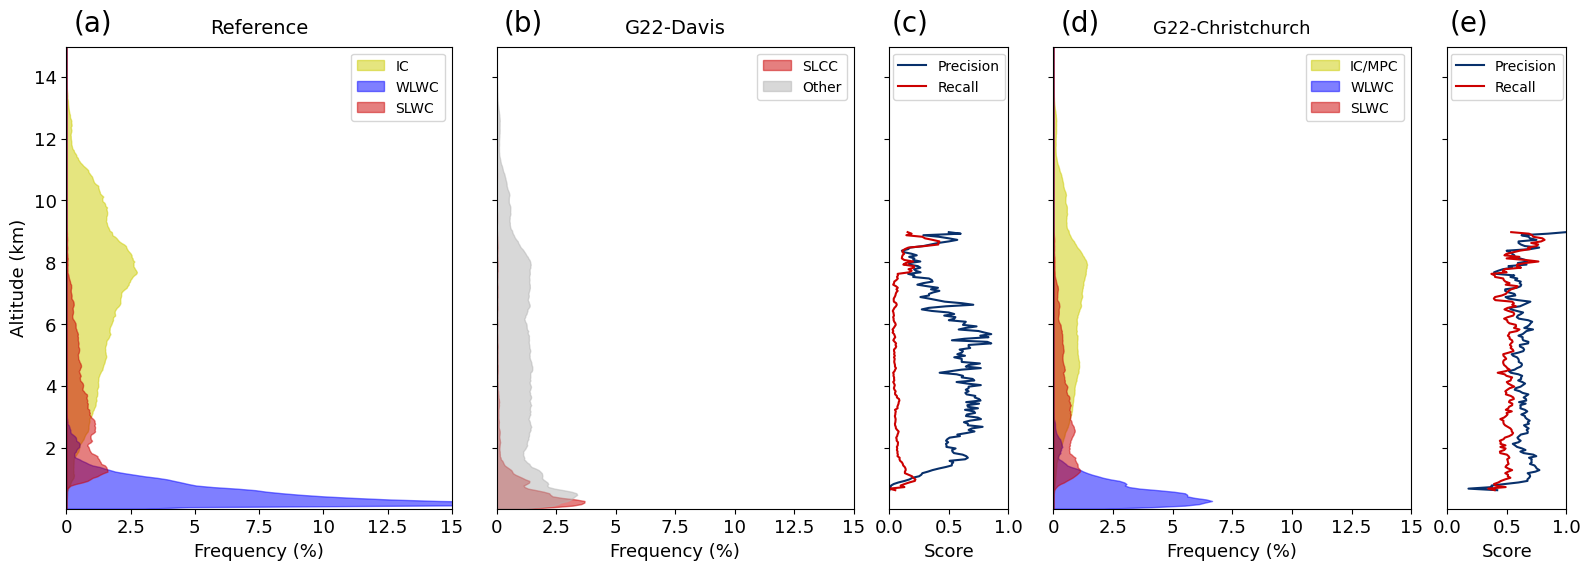

In [59]:
## Model 001

plot_fig(ds_ref_all, ds_mod_all, ds_ag_all)


<Axes: xlabel='Frequency (%)'>

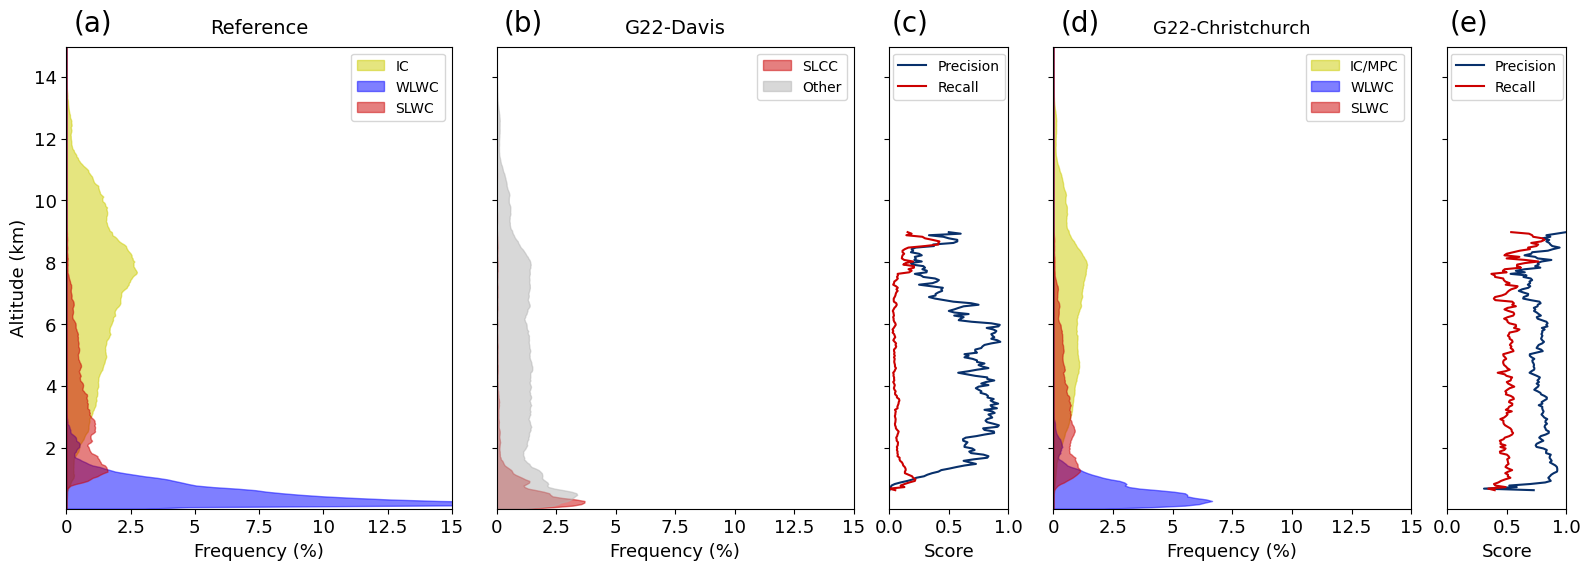

In [70]:
## Model 001, limited to cloud mask

plot_fig(ds_ref_all, ds_mod_all, ds_ag_all)


<Axes: xlabel='Frequency (%)'>

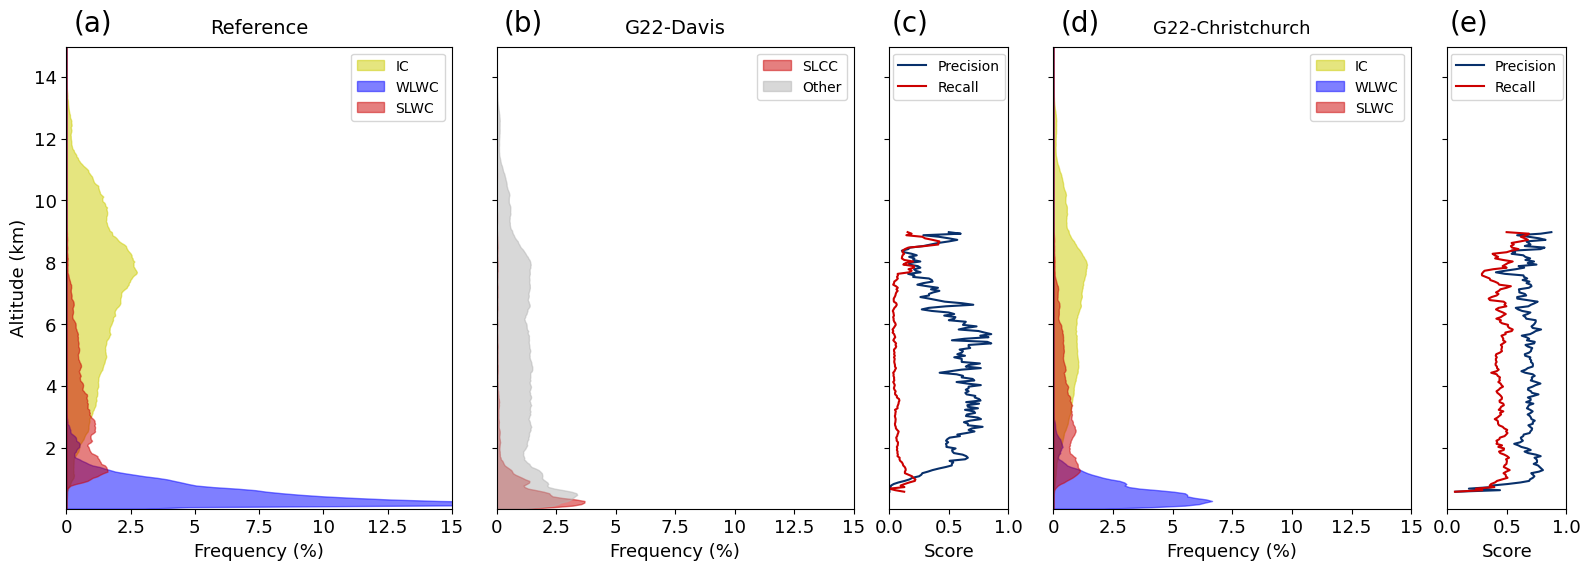

In [15]:
## Model 002
plot_fig(ds_ref_all, ds_mod_all, ds_ag_all)

<Axes: xlabel='Frequency (%)'>

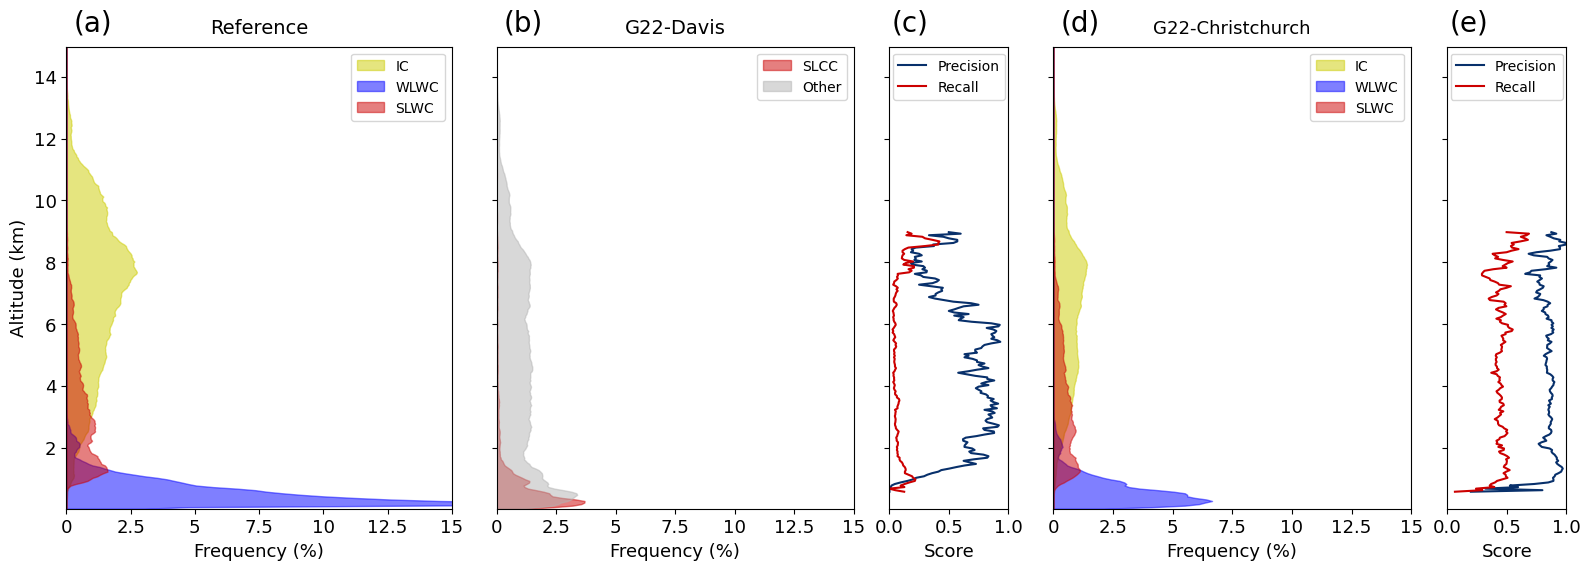

In [13]:
## Model 002, limited to cloud mask

plot_fig(ds_ref_all, ds_mod_all, ds_ag_all)


In [56]:
ds_mod_all.classified_peaks

y= xr.where(ds_mod_all.classified_peaks==-1,np.nan, ds_mod_all.classified_peaks)

all_peaks = ds_mod_all.classified_peaks>=0
slwc_peaks = ds_mod_all.classified_peaks==1

# slwc_peaks.mean(dim='time')*100
# slwc_peaks.sum(dim='time')*100/all_peaks.sum(dim='time')


In [68]:
x = np.array([1,2,3,4,5,6,7,8])
a = np.array([0,0,1,1,0,0,1,0])

x[a==1]
# a==1

array([3, 4, 7])

<Axes: xlabel='Frequency (%)'>

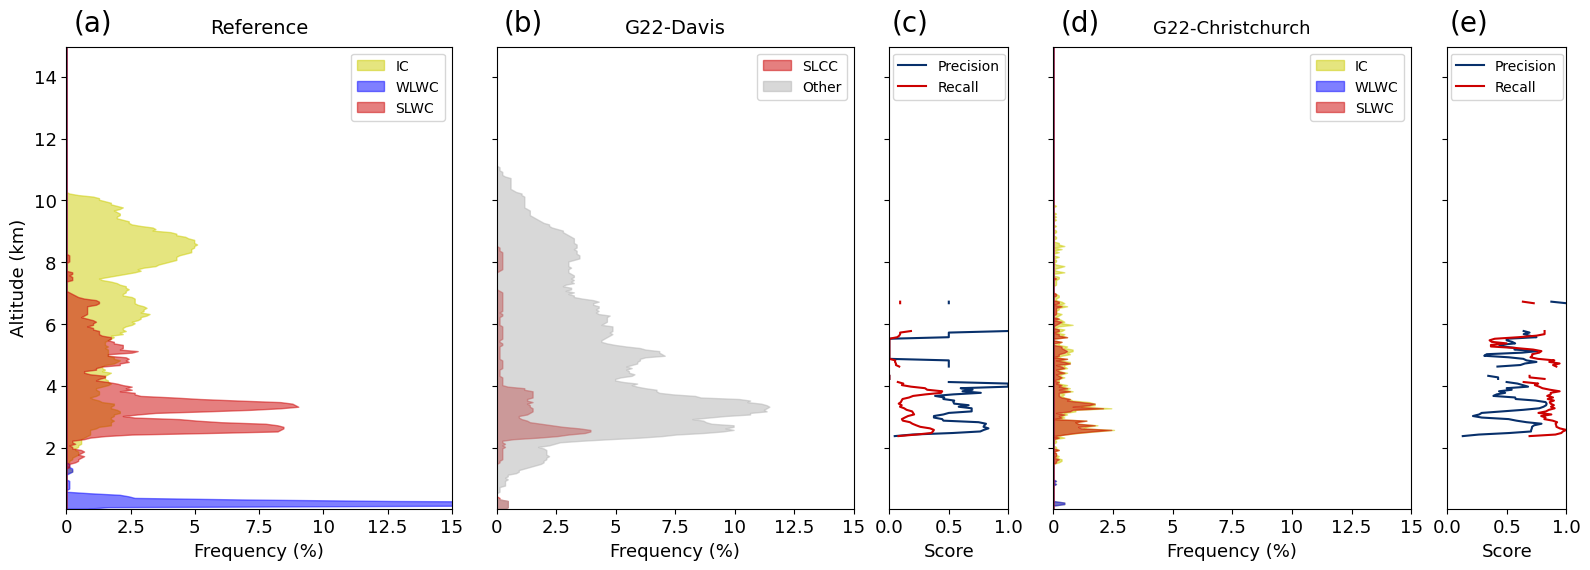

In [52]:
plot_fig(ds_ref_all, ds_mod_all, ds_ag_all)


In [432]:
ds_mod

<xarray.Dataset>
Dimensions:                (time: 288, level: 300)
Coordinates:
  * time                   (time) datetime64[ns] 2022-01-21T00:02:29.999991 ....
    zfull                  (level) float64 ...
Dimensions without coordinates: level
Data variables: (12/13)
    backscatter            (time, level) float64 ...
    cloud_mask             (time, level) int8 ...
    temp                   (time, level) float64 ...
    classified_peaks       (time, level) int8 ...
    classified_peaks_mask  (time, level) int8 ...
    slwc                   (time, level) int8 ...
    ...                     ...
    wlwc                   (time, level) int8 ...
    mpc                    (time, level) int8 ...
    ic                     (time, level) int8 ...
    wlwc_t                 (time) int8 ...
    mpc_t                  (time) int8 ...
    ic_t                   (time) int8 ...

In [362]:
ax3.get_xticklabels().astype(np.int)

AttributeError: 'list' object has no attribute 'astype'